# 로컬 MCP 서버 (개인 메모 관리)

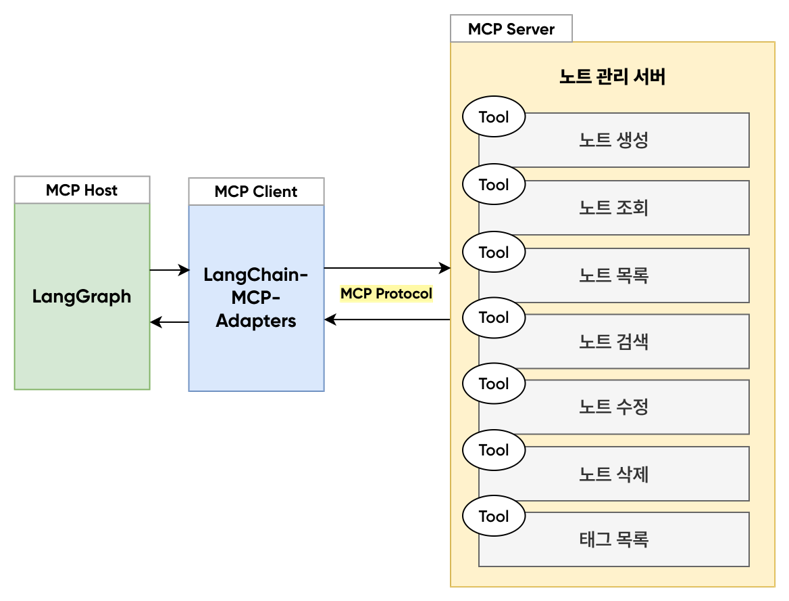


# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 20ms


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# MCP 서버 구성

In [ ]:
from mcp.server.fastmcp import FastMCP   # type: ignore   # FastMCP 서버 클래스를 import
import json                              # JSON 직렬화/역직렬화에 사용
import os                                # (현재 코드에서 직접 사용되지 않음)
from datetime import datetime            # 생성/수정 시각 기록에 사용
from pathlib import Path                 # 파일 경로를 객체로 다루기 위해 사용
from typing import List, Optional        # 타입 힌트에 사용

mcp = FastMCP("NotesManager")            # "NotesManager"라는 이름으로 MCP 서버 인스턴스 생성

# 노트 저장 경로
NOTES_DIR = Path("notes_data")           # 노트 데이터를 저장할 디렉터리 경로
NOTES_FILE = NOTES_DIR / "notes.json"    # 실제 노트가 저장되는 JSON 파일 경로


def ensure_notes_file():
    """노트 파일이 없으면 생성"""
    NOTES_DIR.mkdir(exist_ok=True)       # 디렉터리가 없으면 생성, 이미 있으면 통과
    if not NOTES_FILE.exists():          # JSON 파일이 존재하지 않으면
        with open(NOTES_FILE, "w", encoding="utf-8") as f:
            json.dump([], f)             # 빈 리스트를 저장해 초기 파일 생성


def load_notes() -> list:
    """모든 노트 불러오기"""
    ensure_notes_file()                  # 파일이 없으면 먼저 생성
    with open(NOTES_FILE, "r", encoding="utf-8") as f:
        return json.load(f)              # JSON 파일을 읽어 리스트로 반환


def save_notes(notes: list):
    """노트 저장하기"""
    with open(NOTES_FILE, "w", encoding="utf-8") as f:
        json.dump(notes, f, ensure_ascii=False, indent=2)  # 한글을 유지하고 들여쓰기 2칸으로 저장


@mcp.tool()                              # 이 함수를 MCP 도구로 등록
def create_note(title: str, content: str, tags: Optional[List[str]] = None) -> dict:
    """
    새로운 노트를 생성합니다.

    Args:
        title (str): 노트 제목 (내용과 어울리는 간결한 제목)
        content (str): 노트 내용
        tags (Optional[List[str]]): 태그 리스트 (예: ["업무", "아이디어"], 입력이 없으면 기본값으로 ["기본"] 저장)

    Returns:
        dict: 생성된 노트 정보 (id, title, created_at 포함)
    """
    notes = load_notes()                 # 기존 노트 전체를 불러옴

    note_id = str(len(notes) + 1)        # 현재 노트 개수 + 1을 문자열 ID로 사용
    new_note = {                         # 새 노트 딕셔너리 구성
        "id": note_id,
        "title": title,
        "content": content,
        "tags": tags or ["기본"],        # tags가 None이거나 비어 있으면 ["기본"] 사용
        "created_at": datetime.now().isoformat(),  # 생성 시각을 ISO 형식으로 기록
        "updated_at": datetime.now().isoformat()   # 수정 시각을 생성 시각과 동일하게 초기화
    }

    notes.append(new_note)               # 노트 리스트에 새 노트 추가
    save_notes(notes)                    # 파일에 저장

    return {                             # 생성 결과 요약을 반환
        "id": note_id,
        "title": title,
        "message": f"노트 '{title}'가 생성되었습니다.",
        "created_at": new_note["created_at"]
    }


@mcp.tool()                              # MCP 도구로 등록
def get_note(note_id: str) -> dict:
    """
    특정 노트의 전체 내용을 조회합니다.

    Args:
        note_id (str): 노트 ID

    Returns:
        dict: 노트의 모든 정보
    """
    notes = load_notes()                 # 전체 노트 불러옴

    for note in notes:                   # 노트를 하나씩 순회
        if note["id"] == note_id:        # ID가 일치하는 노트를 찾으면
            return note                   # 해당 노트 전체를 반환

    raise ValueError(f"노트 ID '{note_id}'를 찾을 수 없습니다.")  # 못 찾으면 예외 발생


@mcp.tool()                              # MCP 도구로 등록
def list_notes(tag: Optional[str] = None, limit: int = 10) -> list:
    """
    모든 노트의 목록을 조회합니다.

    Args:
        tag (Optional[str]): 특정 태그로 필터링 (예: "업무")
        limit (int): 반환할 최대 노트 개수 (기본값: 10)

    Returns:
        list: 노트 목록 (id, title, tags, created_at만 포함)
    """
    notes = load_notes()                 # 전체 노트 불러옴

    # 태그로 필터링
    if tag:                              # tag 인자가 주어지면
        notes = [n for n in notes if tag in n.get("tags", [])]  # 해당 태그를 가진 노트만 남김

    # 최신 순으로 정렬
    notes.sort(key=lambda x: x["created_at"], reverse=True)  # created_at 기준 내림차순 정렬

    # 간단한 정보만 반환
    result = []                          # 결과를 담을 리스트
    for note in notes[:limit]:           # limit 개수만큼 순회
        result.append({                  # 요약 정보만 추출해 추가
            "id": note["id"],
            "title": note["title"],
            "tags": note.get("tags", []),
            "created_at": note["created_at"],
            "preview": note["content"][:50] + "..." if len(note["content"]) > 50 else note["content"]  # 내용이 50자 초과면 앞 50자 + "...", 아니면 전체
        })

    return result                        # 요약된 노트 목록 반환


@mcp.tool()                              # MCP 도구로 등록
def search_notes(keyword: str) -> list:
    """
    제목이나 내용에서 키워드를 검색합니다.

    Args:
        keyword (str): 검색할 키워드

    Returns:
        list: 검색된 노트 목록
    """
    notes = load_notes()                 # 전체 노트 불러옴
    keyword_lower = keyword.lower()      # 대소문자 구분 없이 비교하기 위해 소문자로 변환

    results = []                         # 검색 결과를 담을 리스트
    for note in notes:                   # 노트를 하나씩 순회
        title_match = keyword_lower in note["title"].lower()      # 제목에 키워드 포함 여부
        content_match = keyword_lower in note["content"].lower()  # 내용에 키워드 포함 여부

        if title_match or content_match: # 제목 또는 내용 중 하나라도 매치되면
            results.append({             # 결과에 추가
                "id": note["id"],
                "title": note["title"],
                "tags": note.get("tags", []),
                "match_type": "제목" if title_match else "내용",  # 제목이 매치되면 "제목", 아니면 "내용"
                "preview": note["content"][:100] + "..." if len(note["content"]) > 100 else note["content"]  # 내용이 100자 초과면 앞 100자 + "...", 아니면 전체
            })

    return results                       # 검색 결과 반환


@mcp.tool()                              # MCP 도구로 등록
def update_note(note_id: str, title: Optional[str] = None,
                content: Optional[str] = None, tags: Optional[List[str]] = None) -> dict:
    """
    기존 노트를 수정합니다.

    Args:
        note_id (str): 수정할 노트 ID
        title (Optional[str]): 새 제목 (변경하지 않으려면 None)
        content (Optional[str]): 새 내용 (변경하지 않으려면 None)
        tags (Optional[List[str]]): 새 태그 리스트 (변경하지 않으려면 None)

    Returns:
        dict: 수정된 노트 정보
    """
    notes = load_notes()                 # 전체 노트 불러옴

    for note in notes:                   # 노트를 하나씩 순회
        if note["id"] == note_id:        # ID가 일치하는 노트를 찾으면
            if title is not None:        # title 인자가 주어졌으면
                note["title"] = title    # 제목 갱신
            if content is not None:      # content 인자가 주어졌으면
                note["content"] = content  # 내용 갱신
            if tags is not None:         # tags 인자가 주어졌으면
                note["tags"] = tags      # 태그 갱신

            note["updated_at"] = datetime.now().isoformat()  # 수정 시각을 현재 시각으로 갱신
            save_notes(notes)            # 변경 사항 저장

            return {                     # 수정 결과 요약 반환
                "id": note_id,
                "title": note["title"],
                "message": f"노트가 수정되었습니다.",
                "updated_at": note["updated_at"]
            }

    raise ValueError(f"노트 ID '{note_id}'를 찾을 수 없습니다.")  # 못 찾으면 예외 발생


@mcp.tool()                              # MCP 도구로 등록
def delete_note(note_id: str) -> dict:
    """
    노트를 삭제합니다.

    Args:
        note_id (str): 삭제할 노트 ID

    Returns:
        dict: 삭제 결과 메시지
    """
    notes = load_notes()                 # 전체 노트 불러옴

    for i, note in enumerate(notes):     # 인덱스와 함께 노트를 순회
        if note["id"] == note_id:        # ID가 일치하는 노트를 찾으면
            deleted_title = note["title"]  # 삭제 메시지에 쓸 제목을 미리 저장
            notes.pop(i)                 # 해당 인덱스의 노트를 리스트에서 제거
            save_notes(notes)            # 변경 사항 저장

            return {                     # 삭제 결과 반환
                "message": f"노트 '{deleted_title}'가 삭제되었습니다.",
                "deleted_id": note_id
            }

    raise ValueError(f"노트 ID '{note_id}'를 찾을 수 없습니다.")  # 못 찾으면 예외 발생


@mcp.tool()                              # MCP 도구로 등록
def list_all_tags() -> dict:
    """
    모든 노트에서 사용된 태그 목록을 조회합니다.

    Returns:
        dict: 태그와 각 태그의 사용 횟수
    """
    notes = load_notes()                 # 전체 노트 불러옴

    tag_counts = {}                      # 태그별 사용 횟수를 담을 딕셔너리
    for note in notes:                   # 노트를 하나씩 순회
        for tag in note.get("tags", []): # 노트의 태그를 하나씩 순회
            tag_counts[tag] = tag_counts.get(tag, 0) + 1  # 해당 태그의 카운트를 1 증가

    return {                             # 태그 통계 반환
        "total_tags": len(tag_counts),   # 서로 다른 태그의 개수
        "tags": tag_counts               # 태그별 사용 횟수
    }


if __name__ == "__main__":               # 이 파일이 직접 실행될 때만
    mcp.run(transport="streamable-http")           # streamable-http 전송 방식으로 MCP 서버 실행

서버 커기

uv run notes_server.py  

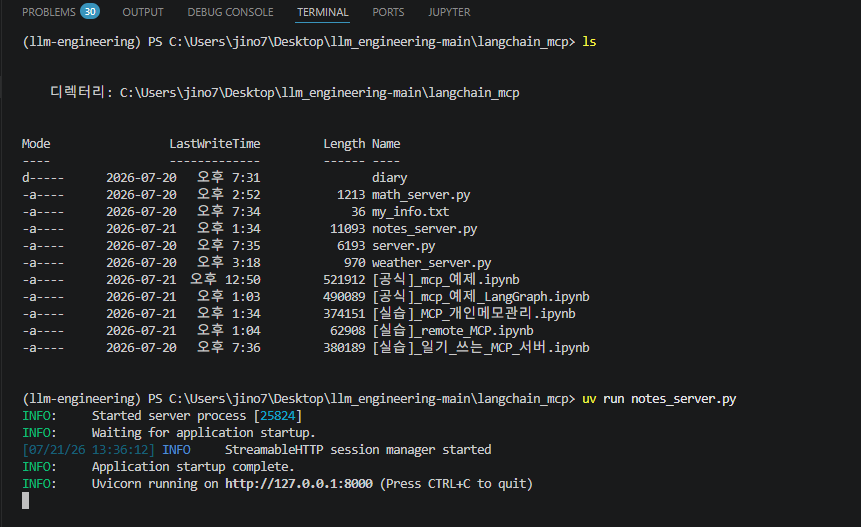

# MCP 클라이언트 구성

In [11]:
# ============================================
# [셀 1] 임포트 및 기본 설정
# ============================================
import gradio as gr
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

# .env 파일의 환경 변수(OPENAI_API_KEY 등)를 프로세스 환경에 로드
load_dotenv()

# 사용할 LLM 모델 정의
model = ChatOpenAI(model="gpt-5-mini")

# 에이전트의 시스템 프롬프트(역할·행동 지침) 문자열
# create_agent에 str로 전달되면 내부에서 SystemMessage로 변환되어
# 매 모델 호출 시 메시지 목록 맨 앞에 추가됨
SYSTEM_PROMPT = (
    "당신은 노트 관리 전문 AI 비서입니다. "
    "사용자의 노트를 생성, 조회, 검색, 수정, 삭제하는 작업을 도와줍니다."
    "사용자로부터 노트의 내용을 중심으로 입력받고, 제목이나 태그가 명시되지 않았다면 자동으로 생성하여 저장하세요."
)

# "note" MCP 서버에 streamable_http 전송 방식으로 연결하는 클라이언트를 생성
# 서버(server.py)는 포트 8000에서 mcp.run(transport="streamable-http")로 실행 중이어야 함
client = MultiServerMCPClient(
    {
        "note": {
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        },
    }
)

# 대화 기록을 저장하는 체크포인터
# 매 요청마다 에이전트를 새로 만들더라도, 같은 thread_id로 조회하면
# 이전 대화 내용이 그대로 이어짐
checkpointer = InMemorySaver()

In [12]:
# ============================================
# [셀 2] Gradio에서 호출할 비동기 응답 함수
# ============================================
async def respond(message, history):
    """
    Gradio ChatInterface가 호출하는 응답 함수.
    message: 사용자가 방금 입력한 텍스트
    history: 지금까지의 화면상 대화 기록 (list)
    """
    # MCP 서버의 tool들을 LangChain tool 형태로 변환
    tools = await client.get_tools()

    # system_prompt로 역할 지침을 전달하여 에이전트 생성
    # 전달한 문자열은 내부에서 SystemMessage로 변환되어 메시지 맨 앞에 추가됨
    agent = create_agent(
        model,
        tools,
        system_prompt=SYSTEM_PROMPT,
        checkpointer=checkpointer,
    )

    # 역할 지침은 system_prompt가 담당하므로 매 턴 사용자 메시지만 전달
    # 이전 대화는 checkpointer가 thread_id 기준으로 복원
    response = await agent.ainvoke(
        {"messages": [{"role": "user", "content": message}]},
        config={"configurable": {"user_id": "user_123", "thread_id": "1"}},
    )

    # 마지막 메시지(최종 AI 응답)의 내용을 반환
    return response["messages"][-1].content

대화 예시
실행 후 다음과 같은 질문을 시도해보세요:

https://examples.com 링크 메모에 저장해줘.

모든 노트 목록 보여줘

'업무' 태그가 있는 노트만 보여줘

"신제품 아이디어"라는 노트를 만들어줘. 태그는 '아이디어', '브레인스토밍

In [13]:
# ============================================
# [셀 3] Gradio UI 실행
# ============================================
demo = gr.ChatInterface(
    fn=respond,                # 비동기 함수도 그대로 전달 가능
    type="messages",           # OpenAI 스타일 messages 형식 사용
    title="MCP 노트 비서",
    description="대화를 마치면 노트로 저장해 드립니다.",
)

# 주피터 노트북에서는 launch() 호출 시 셀 출력 영역에 UI가 인라인으로 표시됨
demo.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


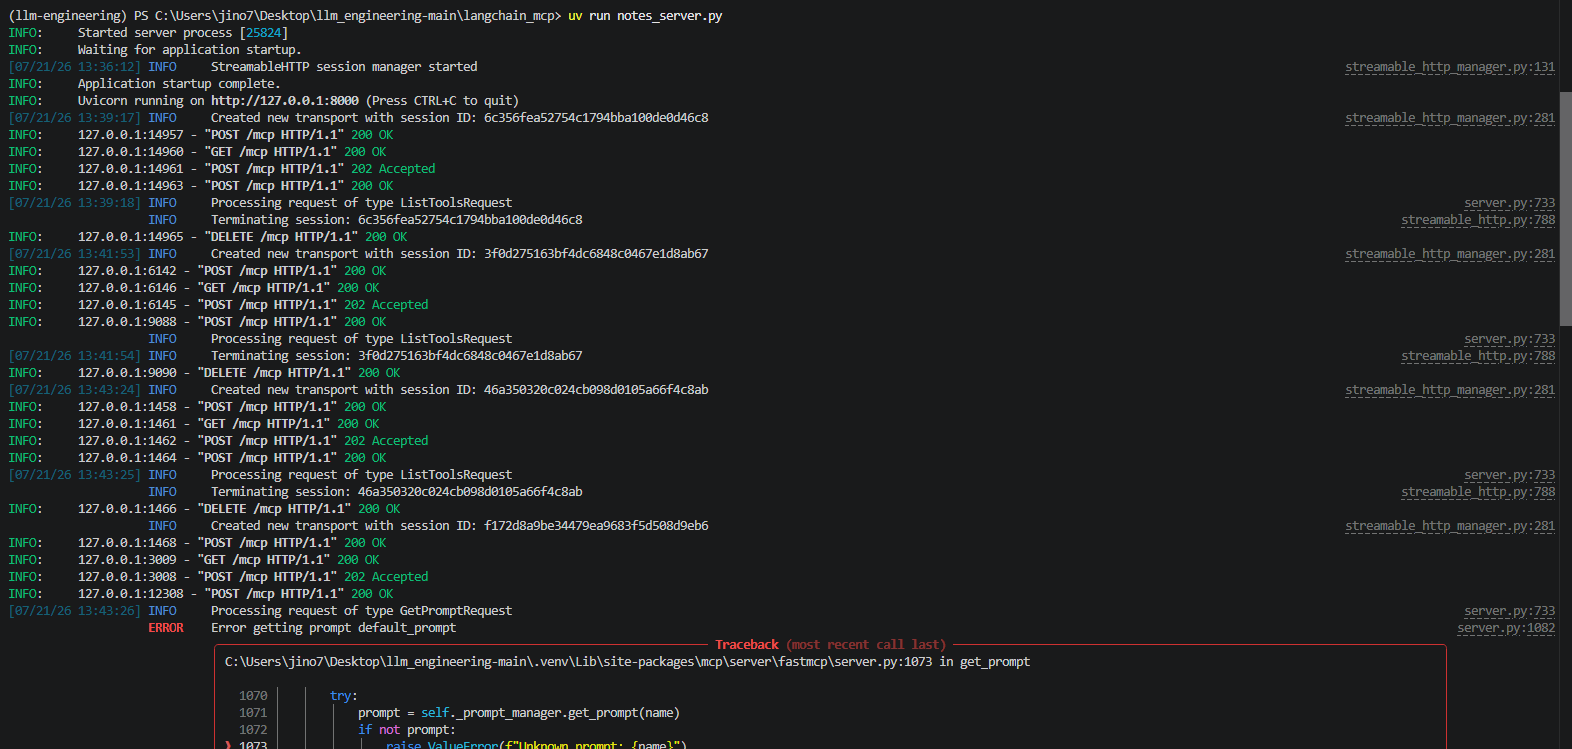